# E97 · Is the sea rising or is the city sinking? Tide gauge, altimetry and GPS at Galveston

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: 118 years of monthly sea level at the **Galveston Pier 21** tide gauge (PSMSL station 161), the NOAA Laboratory for Satellite Altimetry **Gulf of Mexico** mean sea level from five altimetry missions (1993-2025), daily heights of the **TXGA** continuous GPS station on Galveston Island (Nevada Geodetic Laboratory, 2005-2026), and NOAA's 2022 sea-level **scenarios** for the gauge |
| **You will learn** | **Sensor fusion** when every instrument sees a *different linear combination* of the hidden states (ocean minus land, ocean alone, land alone) · reading **identifiability** off the observation matrix, era by era · offsets as **nuisance parameters** instead of "cleaning" (altimetry mission biases, GPS antenna changes) · a failure: two noise terms that one instrument sees only as a sum · watching a split go from **prior-only** to **identified** in the posterior, and testing it by **swapping priors** · turning the fused posterior into a 2050 projection compared with NOAA's scenarios |

## The setting

Galveston, on a barrier island off the Texas coast, has one of the longest tide-gauge records in the
Gulf of Mexico. The gauge at Pier 21 has measured sea level since 1908, and over that time the water has
risen by about 0.75 m relative to the pier - roughly four times the global average rise of the twentieth
century (Frederikse et al. 2020 put that at about 1.6 mm per year). Two very different things hide in
that number. The **ocean** has risen, as it has everywhere. And the **land has sunk**: pumping of
groundwater and oil around Houston compacted the clay beneath the region for most of the century, until
the Harris-Galveston Subsidence District (created in 1975) began to restrict pumping. A tide gauge is
bolted to the land, so it sees only the difference, ocean minus land (Douglas 1991; Wöppelmann & Marcos
2016). Kolker, Allison & Hameed (2011) argued that much of the "sea-level rise" along the northern Gulf
coast in the twentieth century was subsidence.

The split matters for decisions. Subsidence answers to groundwater policy; ocean rise does not. NOAA's
2022 Sea Level Rise Technical Report (Sweet et al. 2022) gives five scenarios of relative sea level at
this gauge, from Low to High, which flood-planning studies take as inputs. Since 2010 the Gulf has risen
unusually fast (Yin 2023; Dangendorf et al. 2023), and a planner wants to know whether the recent jump at
Pier 21 is ocean, which the scenarios expect to keep accelerating, or land, which they do not.

Two newer instruments see the parts separately. **Satellite altimetry** measures the height of the sea
surface from space, independent of the land, since late 1992. **GPS** measures the height of the land
itself; the continuous station TXGA on the island has run since 2005. Each instrument sees a different
linear function of two hidden states, ocean $O$ and land $V$:

$$\text{tide gauge} \approx O - V, \qquad \text{altimetry} \approx O, \qquad \text{GPS} \approx V.$$

None of them alone answers the question, and each has its own problems: the altimetry series is a
basin average, not the water at the pier, and it is stitched from five missions with different biases;
the GPS antenna has been changed three times, each change a jump in the record; and before 1993 only the
tide gauge exists, so the split there can come only from prior knowledge. The statistical idea is old -
a linear Gaussian state-space model with several observation equations, as in Kalman filtering - but the
lesson is in watching which combinations of the states the data can see, and when.

| part | question | tool |
|---|---|---|
| A | What does each instrument record? | seasonal cycles, annual means, a first look at the rates |
| B | Which combinations can be identified, and when? | the observation matrix by era; a decadal-rate model; prior predictive |
| C | What does the tide gauge alone say? | a fit with a failure (two noises seen as one) and its fix |
| D | What do altimetry and GPS add? | mission biases and antenna offsets as nuisance parameters; three fits side by side |
| E | Is the model adequate, and is the split real? | diagnostics, posterior predictive checks, a prior swap |
| F | What should Galveston plan for? | a 2050 projection by component against NOAA's 2022 scenarios |

In [1]:
import logging
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt

from pymc_challenges import data

RANDOM_SEED = 97
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8e5bd0", "#c8384e"
INK, MUTED, LIGHT = "#0b0b0b", "#8a8984", "#d9d8d3"
SRC_COL = {"tide_gauge": INK, "altimetry": BLUE, "gps": ORANGE}
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## A. Three instruments, three views

One table holds all three instruments. The tide gauge gives monthly means in millimetres above a fixed
local datum (the PSMSL "Revised Local Reference", about 7 m below the pier's mean level). The altimetry
file gives the Gulf-wide average sea-surface anomaly every ten days or so, one column per mission:
TOPEX/Poseidon, Jason-1, Jason-2, Jason-3 and Sentinel-6 Michael Freilich. The GPS rows are monthly
means of the daily height of the antenna, split into segments wherever the Nevada Geodetic Laboratory's
equipment log records an antenna change. The older station GAL2 (1997-2003) is in the table too.

In [2]:
data.describe("e97_galveston_sea_land")
raw = data.load("e97_galveston_sea_land")
raw["year"] = np.floor(raw.t).astype(int)
raw["month"] = np.floor((raw.t - raw.year) * 12).clip(0, 11).astype(int)
print(raw.groupby(["source", "segment"]).agg(first=("t", "min"), last=("t", "max"), rows=("t", "size"))
      .round(2).to_string())

e97_galveston_sea_land: One row per observation: source (tide_gauge, altimetry, gps), segment (PSMSL161; the altimetry mission TOPEX/Poseidon, Jason-1, Jason-2, Jason-3, Sentinel-6MF; GPS station and antenna period GAL2-1, TXGA-1 to TXGA-4, TXGA antennas changed 2011-06-13, 2017-04-24, 2021-04-28), t (decimal year), value_mm (tide gauge: monthly mean height above the RLR datum, about 7,000 mm, 1908-2025; altimetry: Gulf basin-mean sea-surface anomaly per ~10-day cycle, 1992.8-2025.1; GPS: monthly mean ellipsoidal height of the antenna, up positive, 1997-2003 and 2005-2026), n (days in the month for the tide gauge and GPS, 1 for altimetry).
  source: Three instruments near Galveston, Texas, read 2026-11-04. (1) Tide gauge: Permanent Service for Mean Sea Level (PSMSL, 2026), 'Tide Gauge Data', Revised Local Reference monthly means of station 161 GALVESTON II, PIER 21, TX (the URL); Holgate et al. (2013), J. Coastal Research 29:493-504; free with acknowledgement. (2) Altimetry: NOAA Labor

Two things have to happen before a model sees these numbers. First, sea level has a large **seasonal
cycle** in the Gulf (warm water expands in late summer, and winds pile water against the coast in some
seasons), and an annual mean over a year with missing months is biased by whichever months are missing.
We remove a monthly climatology from each instrument: the average departure of each calendar month from
its own year's mean. Second, we work with **annual means**. The questions are about rates over decades,
and annual values make the latent states small (118 years) and the noise closer to independent. A year
counts if it has at least six months of data.

In [3]:
def deseason(d):
    """Subtract each calendar month's mean departure from its own (segment, year) mean."""
    dep = d.value_mm - d.groupby(["segment", "year"]).value_mm.transform("mean")
    clim = dep.groupby(d.month).mean()
    return d.value_mm - d.month.map(clim), clim


parts, climatologies = [], {}
for src, d in raw.groupby("source"):
    d = d.copy()
    d["ds"], climatologies[src] = deseason(d)
    a = d.groupby(["segment", "year"]).agg(y=("ds", "mean"), months=("month", "nunique")).reset_index()
    a["source"] = src
    parts.append(a)
ann = pd.concat(parts)
ann = ann[(ann.months >= 6) & (ann.year <= 2025)].reset_index(drop=True)
for src, c in climatologies.items():
    print(f"{src:>10}: seasonal range {c.max() - c.min():5.0f} mm (peak in month {c.idxmax() + 1})")
print(ann.groupby(["source", "segment"]).agg(first=("year", "min"), last=("year", "max"), years=("year", "size"))
      .to_string())

 altimetry: seasonal range   133 mm (peak in month 10)
       gps: seasonal range     4 mm (peak in month 1)
tide_gauge: seasonal range   259 mm (peak in month 9)
                           first  last  years
source     segment                           
altimetry  Jason-1          2002  2013     12
           Jason-2          2008  2016      9
           Jason-3          2016  2024      9
           Sentinel-6MF     2021  2024      4
           TOPEX/Poseidon   1993  2005     13
gps        GAL2-1           2002  2002      1
           TXGA-1           2005  2011      7
           TXGA-2           2011  2016      6
           TXGA-3           2017  2020      4
           TXGA-4           2021  2025      5
tide_gauge PSMSL161         1908  2025    118


The seasonal cycle at the pier is twice as large as in the Gulf as a whole (a range of about 260 mm
against 130 mm, both peaking in early autumn): shallow coastal water responds more to wind and heat than the
basin average does. That is the first hint that the altimetry and the gauge do not see the same water. The GPS
has almost no seasonal cycle in height (4 mm).

Two things drop out of the annual table. The altimetry file ends in February 2025, so 2025 has too few months
and the satellites stop at 2024. The old GPS station GAL2 has only one year with six months of data (2002). With
its own free offset, a single annual value carries no information about any rate, so we drop it: in practice
the GPS record begins in mid-2005, and the years 1993-2005 have no measurement of the land at all.

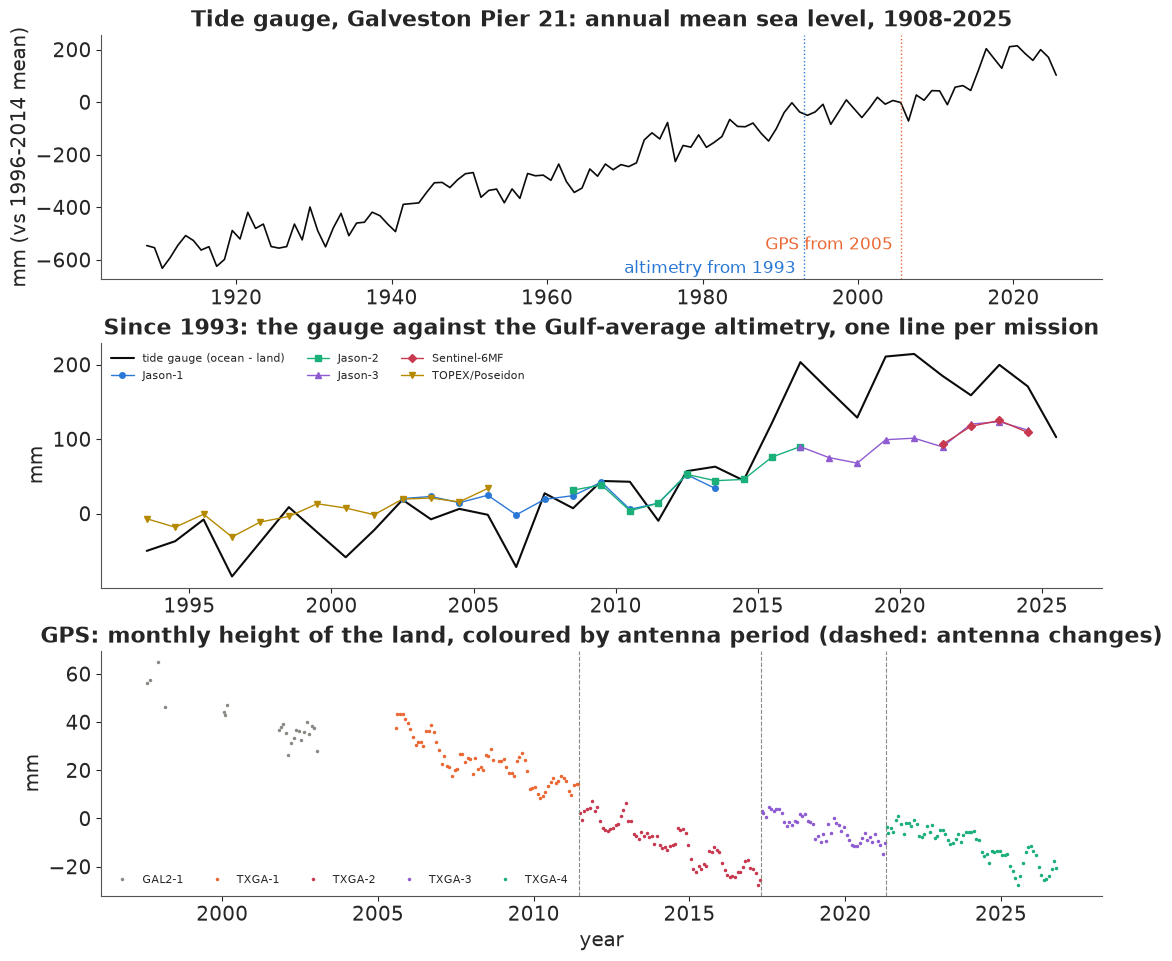

In [4]:
ann = ann[ann.segment != "GAL2-1"].reset_index(drop=True)
TG = ann[ann.source == "tide_gauge"]
ALT = ann[ann.source == "altimetry"]
GPS = ann[ann.source == "gps"]
gps_m = raw[raw.source == "gps"]

fig, axs = plt.subplots(3, 1, figsize=(11, 9.5), layout="constrained")
ax = axs[0]
ax.plot(TG.year + 0.5, TG.y - TG.y[(TG.year >= 1996) & (TG.year <= 2014)].mean(), color=INK, lw=1.2)
ax.axvline(1993, color=BLUE, lw=1, ls=":")
ax.axvline(2005.5, color=ORANGE, lw=1, ls=":")
ax.text(1992, -650, "altimetry from 1993", color=BLUE, ha="right")
ax.text(2004.5, -560, "GPS from 2005", color=ORANGE, ha="right")
ax.set(ylabel="mm (vs 1996-2014 mean)", title="Tide gauge, Galveston Pier 21: annual mean sea level, 1908-2025")
ax = axs[1]
ax.plot(TG.year[TG.year >= 1993] + 0.5, TG.y[TG.year >= 1993] - TG.y[(TG.year >= 1996) & (TG.year <= 2014)].mean(),
        color=INK, lw=1.5, label="tide gauge (ocean - land)")
MISSION_STYLE = list(zip([BLUE, AQUA, PURPLE, RED, "#b58900"], "os^Dv"))
for (m, d), (col, mk) in zip(ALT.groupby("segment", sort=False), MISSION_STYLE):
    ax.plot(d.year + 0.5, d.y, mk + "-", ms=4, lw=1, color=col, label=m)
ax.set(ylabel="mm", title="Since 1993: the gauge against the Gulf-average altimetry, one line per mission")
ax.legend(ncols=3, fontsize=8, loc="upper left")
ax = axs[2]
station = gps_m.segment.str[:4]
for i, (s, d) in enumerate(gps_m.groupby("segment")):
    ref = gps_m.value_mm[station == s[:4]].mean() - (40 if s.startswith("GAL2") else 0)   # each station centred
    ax.plot(d.t, d.value_mm - ref, ".", ms=3, color=[MUTED, ORANGE, RED, PURPLE, AQUA][i], label=s)
for t_ch in [2011.446, 2017.309, 2021.32]:
    ax.axvline(t_ch, color=MUTED, lw=0.8, ls="--")
ax.set(ylabel="mm", xlabel="year", title="GPS: monthly height of the land, coloured by antenna period (dashed: antenna changes)")
ax.legend(ncols=5, fontsize=8, loc="lower left");

The top panel is the century: about 0.75 m of relative rise, steady on average but with decades that run faster
(the late 1930s, the late 1960s and early 1970s, the 2010s). The middle panel is the satellite era. Until about
2010 the gauge and the Gulf average move together, with the gauge pulling slowly ahead; after 2014 the gauge
climbs about 10 cm above the altimetry within two years and stays above it. The bottom panel is the land, seen
by GPS: a steady decline of a few millimetres a year, interrupted by jumps at the antenna changes - the April
2017 one lifts the series by roughly 25 mm. (GAL2, a different antenna on a different monument, is drawn at an
arbitrary height.)

A first look at the rates: ordinary least-squares slopes over common periods. For GPS we fit one slope
with a separate intercept per antenna period, which is the simplest way to stop the jumps from biasing it.

In [5]:
def ols_rate(d, by_segment=False):
    X = [d.year.to_numpy() - 2005.0]
    if by_segment:
        X += [(d.segment == s).to_numpy(float) for s in sorted(d.segment.unique())]
    else:
        X += [np.ones(len(d))]
    X = np.column_stack(X)
    beta, res, *_ = np.linalg.lstsq(X, d.y.to_numpy(), rcond=None)
    resid = d.y.to_numpy() - X @ beta
    cov = resid @ resid / (len(d) - X.shape[1]) * np.linalg.inv(X.T @ X)
    return beta[0], np.sqrt(cov[0, 0])


rows = []
for lo, hi in [(1908, 2025), (1908, 1992), (1993, 2025), (2006, 2025)]:
    sel = lambda d: d[(d.year >= lo) & (d.year <= hi)]
    r_tg = ols_rate(sel(TG))
    r_alt = ols_rate(sel(ALT), by_segment=True) if lo >= 1993 else (np.nan, np.nan)
    r_gps = ols_rate(sel(GPS), by_segment=True) if lo >= 2005 else (np.nan, np.nan)
    rows.append({"period": f"{lo}-{hi}", "tide gauge": f"{r_tg[0]:.1f} ± {r_tg[1]:.1f}",
                 "altimetry": "-" if np.isnan(r_alt[0]) else f"{r_alt[0]:.1f} ± {r_alt[1]:.1f}",
                 "GPS (land)": "-" if np.isnan(r_gps[0]) else f"{r_gps[0]:.1f} ± {r_gps[1]:.1f}"})
print("least-squares rates, mm per year (± naive standard error)")
print(pd.DataFrame(rows).to_string(index=False))
r_naive = ols_rate(GPS[GPS.year >= 2006])
print(f"GPS 2006-2025 with ONE intercept (antenna changes ignored): {r_naive[0]:.1f} ± {r_naive[1]:.1f} mm/yr")

least-squares rates, mm per year (± naive standard error)
   period tide gauge altimetry GPS (land)
1908-2025  6.6 ± 0.1         -          -
1908-1992  6.4 ± 0.2         -          -
1993-2025  8.4 ± 0.8 3.8 ± 0.7          -
2006-2025 11.7 ± 1.9 5.9 ± 1.2 -4.2 ± 0.3
GPS 2006-2025 with ONE intercept (antenna changes ignored): -2.0 ± 0.4 mm/yr


These rates already tell most of the story, and they disagree with one another, as they must. Over 2006-2025
the gauge rose by 11.7 mm/yr, the Gulf by 5.9 mm/yr, and the land fell by 4.2 mm/yr; ocean minus land is
5.9 + 4.2 = 10.1 mm/yr, 1.6 short of the gauge's 11.7 but well within the gauge's own standard error of 1.9.
The altimetry rate since 1993 is 3.8 mm/yr, below the 4.32 mm/yr that NOAA states in the header of the file at
the URL (quoted in the data source note above; the cached table drops the header), because our fit
gives each mission its own intercept: letting the joins between missions float costs information, and we will
pay that price in the model too. The same goes for the GPS, the other way round: with one intercept, ignoring
the antenna changes, the land rate comes out at -2.0 mm/yr, half the -4.2 of the fit with one intercept per
antenna period. The standard errors here assume independent years, which the gauge's
year-to-year wobbles are not, so they are a little optimistic.

What least squares cannot do is say how the 6.4 mm/yr of relative rise before 1993 divides into ocean and
land, or how sure we should be of the split after 1993. For that we need one model of all three instruments.

## B. Which combinations can the data see?

### The states

We describe three hidden time series, each set to zero at the start of 2005 (the baseline year of NOAA's
scenarios), in millimetres. The **ocean** $O_t$ is the Gulf-average sea surface, the thing the altimeters
measure. The **local departure** $D_t$ is how far the water at Pier 21 runs ahead of or behind the Gulf
average - coastal currents, winds, river water, the Loop Current - plus anything else that differs between
the pier and the basin. The **land** $V_t$ is the height of the ground at the pier, up positive, so
subsidence is a negative rate.

Each state changes at a rate that is constant within a segment of about a decade and can change between
segments. We put the segment boundaries at 1905, 1915, ..., 1985, then at **1993** (when altimetry begins)
and **2005** (when GPS begins), then 2015, and end at 2026. For a rate vector $r$ over the 12 segments the
state in year $t$ is $X_t = \sum_k A_{tk} r_k$, where $A_{tk}$ is the signed time spent in segment $k$
between 2005 and the middle of year $t$. Everything downstream is linear in the rates.

### The observations

With $\eta_t$ a year-to-year wobble of the whole Gulf (seen by the gauge and the altimeters alike), and
separate datums (offsets) $c$ for each series:

$$\begin{aligned}
\text{TG}_t &= c_{\text{TG}} + O_t + D_t - V_t + \eta_t + \varepsilon^{\text{TG}}_t, & \varepsilon^{\text{TG}} &\sim \mathcal N(0, \sigma_{\text{TG}}^2)\\
\text{ALT}_{m,t} &= c_m + O_t + \eta_t + \varepsilon^{\text{ALT}}_{m,t}, & \varepsilon^{\text{ALT}} &\sim \mathcal N(0, \sigma_{\text{ALT}}^2)\\
\text{GPS}_{j,t} &= c_j + V_t + \varepsilon^{\text{GPS}}_{j,t}, & \varepsilon^{\text{GPS}} &\sim \mathcal N(0, \sigma_{\text{GPS}}^2)
\end{aligned}$$

Here $m$ is the altimetry mission and $j$ the GPS antenna period. Each mission and each antenna period
gets its own free offset, so a bias between missions or a jump at an antenna change is absorbed by a
nuisance parameter instead of being "cleaned" by hand. The price is that a series with a free offset only
informs *changes* within itself.

In each era, stack the coefficient rows of $(O, D, V)$ that some instrument observes. The rank of that
matrix is the number of independent combinations of the states the data can pin down.

In [6]:
H_rows = {"tide gauge": [1, 1, -1], "altimetry": [1, 0, 0], "GPS": [0, 0, 1]}
eras = {"1908-1992": ["tide gauge"], "1993-2004": ["tide gauge", "altimetry"],
        "2005-2025": ["tide gauge", "altimetry", "GPS"]}
for era, inst in eras.items():
    H = np.array([H_rows[i] for i in inst])
    print(f"{era}: instruments {', '.join(inst):<32} rank {np.linalg.matrix_rank(H)} of 3")

1908-1992: instruments tide gauge                       rank 1 of 3
1993-2004: instruments tide gauge, altimetry            rank 2 of 3
2005-2025: instruments tide gauge, altimetry, GPS       rank 3 of 3


Before 1993 the data see one combination, $O + D - V$ (relative sea level). From 1993 they see two, so
$O$ is separated from $D - V$, but the local departure and the land are still seen only as a difference:
a tide gauge running ahead of the altimeters could be a sinking pier or a coastal sea rising faster than
the Gulf. Only from 2005 are all three identified. Whatever the posterior says about a combination the
data cannot see comes from the priors - and from the way the priors connect one era to another.

### The priors

The priors carry the physics we are willing to assume. The **ocean rates** follow a random walk backwards in
time from the latest segment: $r^O_{12} \sim \mathcal N(3, 5^2)$ mm/yr (vague), and each earlier segment
differs from the next by $\mathcal N(0, 1^2)$, so the ocean's rate changes smoothly. Before 1993 this prior is
all there is for the ocean: it extrapolates the satellite-era rates backwards, and because each step adds an
independent sd of 1 mm/yr, the spread grows roughly as the square root of the number of decades.

The **land rates** follow the same kind of random walk, $r^V_{12} \sim \mathcal N(0, 5^2)$ with steps
$\mathcal N(0, 1.5^2)$: subsidence can speed up and slow down with pumping. The **local departure rates** are
independent, $r^D_k \sim \mathcal N(0, 2^2)$: a coastal site can run a couple of millimetres a year ahead of
or behind its basin for a decade, but not systematically for a century. The noise scales get
$\sigma_\eta \sim$ HalfNormal(30), $\sigma_{\text{TG}} \sim$ HalfNormal(30), $\sigma_{\text{ALT}} \sim$
HalfNormal(30) and $\sigma_{\text{GPS}} \sim$ HalfNormal(10) mm, and every offset $\mathcal N(\text{series
mean}, 100^2)$.

The structure itself carries an assumption worth naming: $D$ is rough (independent decades) while $O$ and
$V$ are smooth. When only the tide gauge exists, a single decade that sticks out from its neighbours is
therefore most cheaply explained as local departure, not as a change in ocean or land.

In [7]:
YEARS = np.arange(1908, 2026)
EDGES = np.array([1905, 1915, 1925, 1935, 1945, 1955, 1965, 1975, 1985, 1993, 2005, 2015, 2026.0])
SEG = [f"{int(a)}-{int(b) - 1}" for a, b in zip(EDGES[:-1], EDGES[1:])]
SEG[-1] = "2015-2025"
A = np.column_stack([np.clip(YEARS + 0.5, lo, hi) - np.clip(2005.0, lo, hi) for lo, hi in zip(EDGES[:-1], EDGES[1:])])
K = len(SEG)
SEG_MID = 0.5 * (np.maximum(EDGES[:-1], 1908) + np.minimum(EDGES[1:], 2026))


def random_walk_back(name, last_mu, last_sd, step_sd):
    """Rates per segment: the last one free, earlier ones a random walk backwards from it."""
    last = pm.Normal(f"{name}_last", last_mu, last_sd)
    steps = pm.Normal(f"{name}_step", 0, step_sd, shape=K - 1)
    return pt.concatenate([last + pt.cumsum(steps[::-1])[::-1], last[None]])


def build_model(sources=("tide_gauge", "altimetry", "gps"), wobble=True, ocean_prior="smooth",
                one_alt_offset=False):
    d = ann[ann.source.isin(sources)].reset_index(drop=True)
    if one_alt_offset:                       # all five missions share one datum
        d.loc[d.source == "altimetry", "segment"] = "altimetry"
    yi = (d.year - YEARS[0]).to_numpy()
    src = d.source.to_numpy()
    series = list(dict.fromkeys(d.segment))
    si = pd.Index(series).get_indexer(d.segment)
    centre = d.groupby("segment").y.mean().reindex(series).to_numpy()
    coords = {"seg": SEG, "year": YEARS, "series": series, "obs": np.arange(len(d))}
    with pm.Model(coords=coords) as m:
        if ocean_prior == "smooth":
            rO = random_walk_back("rO", 3.0, 5.0, 1.0)
        else:  # "global": before 1993 the global-mean rate of Frederikse et al. (2020); vague afterwards
            pre = pm.Normal("rO_pre1993", 1.6, 0.5, shape=K - 3)
            post = pm.Normal("rO_post1993", 3.0, 5.0, shape=3)
            rO = pt.concatenate([pre, post])
        rO = pm.Deterministic("rO", rO, dims="seg")
        rV = pm.Deterministic("rV", random_walk_back("rV", 0.0, 5.0, 1.5), dims="seg")
        rD = pm.Normal("rD", 0.0, 2.0, dims="seg")
        O = pm.Deterministic("O", pt.dot(A, rO), dims="year")
        D = pm.Deterministic("D", pt.dot(A, rD), dims="year")
        V = pm.Deterministic("V", pt.dot(A, rV), dims="year")
        if wobble:
            s_eta = pm.HalfNormal("s_eta", 30.0)
            eta = pm.Deterministic("eta", s_eta * pm.Normal("eta_z", 0, 1, dims="year"), dims="year")
        else:
            eta = pt.zeros(len(YEARS))
        offset = pm.Normal("offset", centre, 100.0, dims="series")
        sigma = {"tide_gauge": pm.HalfNormal("s_tg", 30.0), "altimetry": pm.HalfNormal("s_alt", 30.0),
                 "gps": pm.HalfNormal("s_gps", 10.0)}
        tg_state, alt_state, gps_state = O + D - V + eta, O + eta, V
        state = pt.zeros(len(d))
        sd = pt.zeros(len(d))
        for s, st in [("tide_gauge", tg_state), ("altimetry", alt_state), ("gps", gps_state)]:
            rows_s = np.where(src == s)[0]
            if len(rows_s):
                state = pt.set_subtensor(state[rows_s], st[yi[rows_s]])
                sd = pt.set_subtensor(sd[rows_s], sigma[s])
        pm.Normal("y", offset[si] + state, sd, observed=d.y.to_numpy(), dims="obs")
    m.rows = d
    return m


m_all = build_model()
print(f"full model: {len(m_all.rows)} annual values, {len(m_all.free_RVs)} free variables, "
      f"{sum(int(np.prod(m_all.initial_point()[v.name].shape)) for v in m_all.value_vars)} parameters")

full model: 187 annual values, 11 free variables, 168 parameters


### Prior predictive check

Do these priors produce plausible sea-level histories at the pier? We draw from the prior of the full
model and look at the implied relative sea level $O + D - V$ (without the wobble) and its century rate.

prior relative-sea-level rate 1908-2025, mm/yr: 5/50/95% = [-9.6  2.5 15.8]
share of prior draws with a century rate between 0 and 15 mm/yr: 0.59


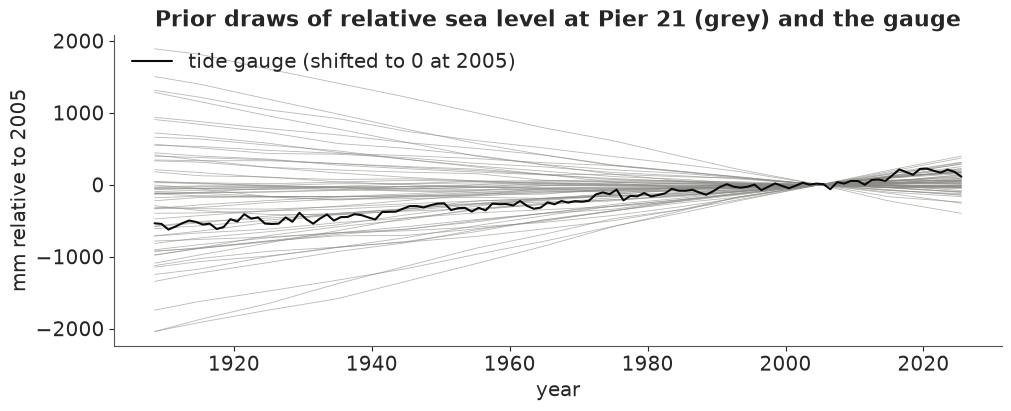

In [8]:
with m_all:
    prior = pm.sample_prior_predictive(500, random_seed=RANDOM_SEED)
rsl_prior = (prior.prior["O"] + prior.prior["D"] - prior.prior["V"]).values.reshape(-1, len(YEARS))
century = (rsl_prior[:, -1] - rsl_prior[:, 0]) / (YEARS[-1] - YEARS[0])
print("prior relative-sea-level rate 1908-2025, mm/yr: 5/50/95% =", np.round(np.percentile(century, [5, 50, 95]), 1))
print(f"share of prior draws with a century rate between 0 and 15 mm/yr: {np.mean((century > 0) & (century < 15)):.2f}")

fig, ax = plt.subplots(figsize=(10, 4))
for k in range(60):
    ax.plot(YEARS + 0.5, rsl_prior[k], color=MUTED, lw=0.6, alpha=0.6)
ax.plot(TG.year + 0.5, TG.y - TG.y[TG.year.between(2003, 2007)].mean(), color=INK, lw=1.5, label="tide gauge (shifted to 0 at 2005)")
ax.set(xlabel="year", ylabel="mm relative to 2005", title="Prior draws of relative sea level at Pier 21 (grey) and the gauge")
ax.legend(loc="upper left");

The prior is deliberately loose on the relative rate - the 90% range of the century rate runs from about -10
to +16 mm/yr, and only 59% of draws fall between 0 and 15 - because the gauge pins that combination down
precisely whatever the prior says. The priors that matter are the ones on the split, and those we keep in
view throughout: the grey bands in the figures of part D are exactly these priors.

## C. The tide gauge alone

We start where a twentieth-century analyst would have: only the gauge. The model is the same, with the
altimetry and GPS rows removed.

In [9]:
def fit(model, **kw):
    t0 = time.time()
    with model:
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, tune=kw.pop("tune", 1000), **kw)
    idata.attrs["seconds"] = time.time() - t0
    return idata


def health(idata, name):
    post = idata.posterior
    rh = max(float(az.rhat(post[v]).max()) for v in ["rO", "rD", "rV"])
    ess = min(float(az.ess(post[v]).min()) for v in ["rO", "rD", "rV"])
    div = int(idata.sample_stats["diverging"].sum())
    print(f"{name:<24} {idata.attrs['seconds']:4.0f} s  divergences {div:4d}  max r_hat {rh:.3f}  "
          f"min bulk ESS {ess:5.0f}  tuning steps {post.attrs.get('tuning_steps', '?')}")


idata_tg_bad = fit(build_model(sources=("tide_gauge",)), tune=400)
health(idata_tg_bad, "gauge only, with wobble")
print("s_eta vs s_tg correlation across draws:",
      round(float(np.corrcoef(idata_tg_bad.posterior["s_eta"].values.ravel(),
                              idata_tg_bad.posterior["s_tg"].values.ravel())[0, 1]), 2))

gauge only, with wobble    14 s  divergences  566  max r_hat 1.287  min bulk ESS    10  tuning steps 400
s_eta vs s_tg correlation across draws: -0.88


### Failure 1: two noises that one instrument sees as one

566 divergences, an r_hat of 1.29 and a bulk ESS of 10: this fit is broken, and the scatter shows why. The
gauge-only model contains two independent year-to-year noises, the Gulf-wide wobble $\eta_t$ and the gauge's
own noise $\varepsilon^{\text{TG}}_t$. The gauge sees only their sum, so the data fix $\sigma_\eta^2 +
\sigma_{\text{TG}}^2$ and nothing else: the posterior is a ridge along a quarter circle (the two scales
correlate at -0.88 across draws). Where $\sigma_{\text{TG}}$ is small, the 118 latent wobbles $\eta_t$ have
to carry all the noise and their own scale becomes a funnel; that is where the red divergent draws sit.

It is the same identifiability problem as the ocean-land split, one level down: two terms that the instrument
sees only as a sum. In the full model the altimeters see $\eta_t$ without the gauge's noise, so the two
scales separate.

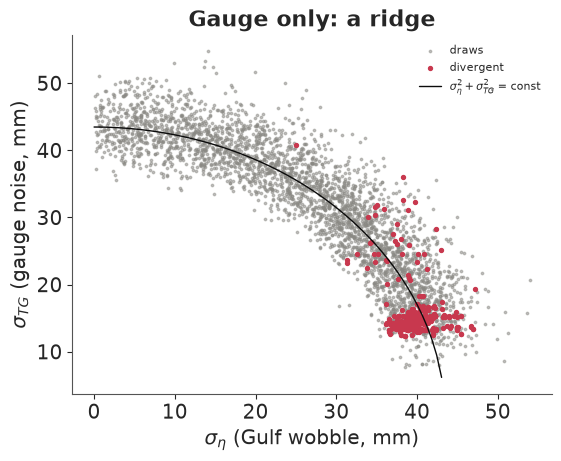

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
p = idata_tg_bad.posterior
div = idata_tg_bad.sample_stats["diverging"].values.ravel()
ax.scatter(p["s_eta"].values.ravel()[~div], p["s_tg"].values.ravel()[~div], s=3, color=MUTED, alpha=0.5, label="draws")
ax.scatter(p["s_eta"].values.ravel()[div], p["s_tg"].values.ravel()[div], s=8, color=RED, label="divergent")
tt = np.linspace(0, 60, 100)
tot = np.sqrt(np.median(p["s_eta"].values ** 2 + p["s_tg"].values ** 2))
ax.plot(tt[tt < tot], np.sqrt(tot ** 2 - tt[tt < tot] ** 2), color=INK, lw=1, label=r"$\sigma_\eta^2+\sigma_{TG}^2$ = const")
ax.set(xlabel=r"$\sigma_\eta$ (Gulf wobble, mm)", ylabel=r"$\sigma_{TG}$ (gauge noise, mm)", title="Gauge only: a ridge")
ax.legend(fontsize=8);

The fix is to not ask the gauge-only data a question they cannot answer. Without a second instrument, the
wobble is merged into the gauge noise (one $\sigma$, no $\eta_t$). An informative prior on one of the two
scales would also work, but it would only be repeating the prior back to us.

In [11]:
idata_tg = fit(build_model(sources=("tide_gauge",), wobble=False), target_accept=0.95)
health(idata_tg, "gauge only, no wobble")


def rate_table(idata, names=("rO", "rD", "rV")):
    p = idata.posterior
    out = {}
    for v in names:
        mu, sd = p[v].mean(("chain", "draw")).values, p[v].std(("chain", "draw")).values
        out[v] = [f"{a:5.1f} ± {b:3.1f}" for a, b in zip(mu, sd)]
    rel = (p["rO"] + p["rD"] - p["rV"])
    out["relative"] = [f"{a:5.1f} ± {b:3.1f}" for a, b in zip(rel.mean(("chain", "draw")).values, rel.std(("chain", "draw")).values)]
    return pd.DataFrame(out, index=SEG).rename(columns={"rO": "ocean", "rD": "departure", "rV": "land"})


print("posterior rates, mm/yr (mean ± sd), gauge only")
print(rate_table(idata_tg).to_string())

gauge only, no wobble      11 s  divergences    0  max r_hat 1.005  min bulk ESS   700  tuning steps 1000
posterior rates, mm/yr (mean ± sd), gauge only
                 ocean    departure         land     relative
1905-1914    4.7 ± 4.6   -0.2 ± 1.8   -0.1 ± 4.8    4.6 ± 2.6
1915-1924    4.8 ± 4.5   -0.5 ± 1.8   -0.2 ± 4.6    4.5 ± 1.6
1925-1934    5.0 ± 4.4   -0.6 ± 1.8   -0.7 ± 4.5    5.1 ± 1.6
1935-1944    5.3 ± 4.4    2.2 ± 1.7   -1.4 ± 4.4    9.0 ± 1.6
1945-1954    5.1 ± 4.3   -1.2 ± 1.7   -0.9 ± 4.4    4.9 ± 1.6
1955-1964    5.2 ± 4.2   -1.0 ± 1.7   -1.1 ± 4.2    5.2 ± 1.6
1965-1974    5.5 ± 4.1    1.8 ± 1.7   -1.8 ± 4.2    9.1 ± 1.5
1975-1984    5.4 ± 4.0   -0.2 ± 1.7   -1.5 ± 4.1    6.7 ± 1.5
1985-1992    5.3 ± 3.9   -0.2 ± 1.8   -1.4 ± 4.0    6.5 ± 1.8
1993-2004    5.3 ± 3.8   -2.0 ± 1.7   -1.3 ± 3.9    4.6 ± 1.4
2005-2014    5.8 ± 3.8    1.8 ± 1.8   -2.3 ± 3.8   10.0 ± 1.6
2015-2025    5.8 ± 3.7    0.5 ± 1.8   -2.4 ± 3.7    8.8 ± 1.9


The fit is now clean (0 divergences, r_hat 1.005). Read the table by columns. The **relative** rate is well
determined in every decade, to about ±1.5 mm/yr: 4.5-5 mm/yr in the early century, 9 in the decades centred on
1940 and 1970, 10 in 2005-2014, 9 in 2015-2025. The **ocean** and **land** columns are another matter. Their
sds of 3.7-4.8 mm/yr are close to the prior's, and their means (ocean about 5, land between 0 and -2.4) are just
the prior's shape shifted so that their difference matches the gauge. On its own the gauge says nothing about
whether Galveston's water is rising or its pier sinking.

The **departure** column shows a quieter effect of the priors. The decades whose relative rate sticks out
(1935-1944, 1965-1974 and 2005-2014 high, 1993-2004 low) get departures of about ±2 mm/yr. Nothing in the data
says those bumps are local water rather than ocean or land; the model puts them there because we made $D$ the
only rough component. That is a modelling choice, and the next instruments will test part of it.

## D. Adding the satellites and the GPS

Now the altimetry rows go in: five missions, each with its own offset. Consecutive missions overlap for
years at a time in this file (TOPEX/Poseidon and Jason-1 in 2002-2005, Jason-1 and Jason-2 in 2008-2013,
Jason-2 and Jason-3 in 2016-2017, Jason-3 and Sentinel-6 from 2021), and in an overlap both missions see the
same $O_t + \eta_t$, so the difference of their offsets is pinned down directly. The tide gauge, running
underneath all of them, ties the joins as well. That is the honest version of the "inter-mission bias"
problem: the joins are estimated, with uncertainty, from the overlaps, instead of being assumed.

In [12]:
idata_ta = fit(build_model(sources=("tide_gauge", "altimetry")), target_accept=0.95)
health(idata_ta, "gauge + altimetry")
print(rate_table(idata_ta).to_string())

gauge + altimetry           9 s  divergences    0  max r_hat 1.021  min bulk ESS   183  tuning steps 1000
                 ocean    departure         land     relative
1905-1914    2.9 ± 2.6   -0.3 ± 1.9   -1.9 ± 2.9    4.5 ± 2.5
1915-1924    2.9 ± 2.5   -0.5 ± 1.8   -2.1 ± 2.7    4.5 ± 1.6
1925-1934    3.2 ± 2.3   -0.6 ± 1.7   -2.5 ± 2.5    5.1 ± 1.5
1935-1944    3.5 ± 2.2    2.3 ± 1.7   -3.3 ± 2.4    9.1 ± 1.5
1945-1954    3.3 ± 2.0   -1.2 ± 1.7   -2.7 ± 2.2    4.8 ± 1.5
1955-1964    3.3 ± 1.8   -1.1 ± 1.7   -3.0 ± 2.1    5.2 ± 1.5
1965-1974    3.6 ± 1.7    1.8 ± 1.7   -3.7 ± 1.9    9.1 ± 1.6
1975-1984    3.5 ± 1.4   -0.2 ± 1.8   -3.3 ± 1.8    6.7 ± 1.5
1985-1992    3.4 ± 1.1   -0.2 ± 1.8   -3.2 ± 1.6    6.4 ± 1.7
1993-2004    3.3 ± 0.6   -1.8 ± 1.7   -3.1 ± 1.4    4.6 ± 1.4
2005-2014    4.3 ± 0.5    1.9 ± 1.7   -3.9 ± 1.4   10.1 ± 1.6
2015-2025    5.0 ± 0.8    0.0 ± 1.8   -3.6 ± 1.7    8.7 ± 1.9


With the satellites the ocean is pinned down from 1993: 3.3 ± 0.6 mm/yr in 1993-2004, 4.3 ± 0.5 in 2005-2014
and 5.0 ± 0.8 in 2015-2025 - a Gulf that has been speeding up. (Part E will show that these sds owe a good
deal to the smooth prior.) Before 1993 the ocean column also moved, from about 5 to about 3 mm/yr, with sds
of 1-2.6 instead of 4. No satellite saw those decades; the random-walk prior carries the measured 1990s
rate backwards, and its sd widens by about half a millimetre a year for the first decade back and by less
for each one after, as a random walk's should. This is information the prior *transports*, not information
the data contain about the 1950s.

The land column is still loose after 1993: -3.1 ± 1.4, -3.9 ± 1.4 and -3.6 ± 1.7 mm/yr. Altimetry fixes $O$,
and the gauge then fixes $D - V$, but between a coastal sea that runs ahead of the Gulf and a sinking pier
the data cannot choose. Only the prior on $D$ (sd 2 mm/yr) stops the land rate from wandering further.

Finally the GPS. TXGA's four antenna periods each get a free offset. The jump at the April 2017 antenna
change is about 26 mm in the daily data (Hurricane Harvey's flooding came four months later and shows no
step), the size of six years of subsidence. The last line of the least-squares cell in part A shows what
ignoring the antenna changes does to the land rate.

In [13]:
idata_all = fit(m_all, target_accept=0.95)
health(idata_all, "gauge + altimetry + GPS")
print(rate_table(idata_all).to_string())
print(az.summary(idata_all, var_names=["s_eta", "s_tg", "s_alt", "s_gps"], round_to=3).to_string())

gauge + altimetry + GPS     9 s  divergences    0  max r_hat 1.020  min bulk ESS   216  tuning steps 1000
                 ocean    departure         land     relative
1905-1914    2.6 ± 2.7   -0.3 ± 1.9   -2.2 ± 3.0    4.5 ± 2.5
1915-1924    2.7 ± 2.5   -0.5 ± 1.8   -2.3 ± 2.7    4.5 ± 1.6
1925-1934    2.9 ± 2.4   -0.6 ± 1.7   -2.8 ± 2.5    5.1 ± 1.5
1935-1944    3.3 ± 2.2    2.3 ± 1.7   -3.6 ± 2.3    9.2 ± 1.6
1945-1954    3.1 ± 2.0   -1.3 ± 1.8   -3.0 ± 2.2    4.7 ± 1.5
1955-1964    3.2 ± 1.8   -1.1 ± 1.7   -3.1 ± 2.0    5.2 ± 1.6
1965-1974    3.4 ± 1.7    1.9 ± 1.7   -3.8 ± 1.8    9.1 ± 1.6
1975-1984    3.3 ± 1.4   -0.1 ± 1.7   -3.4 ± 1.6    6.7 ± 1.5
1985-1992    3.3 ± 1.1   -0.1 ± 1.8   -3.2 ± 1.4    6.3 ± 1.8
1993-2004    3.3 ± 0.6   -2.0 ± 1.5   -3.2 ± 1.2    4.6 ± 1.4
2005-2014    4.3 ± 0.5    1.5 ± 1.4   -4.5 ± 0.4   10.3 ± 1.5
2015-2025    5.1 ± 0.8   -0.2 ± 1.7   -4.0 ± 0.5    8.9 ± 1.8
         mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd


The land is now measured: **-4.5 ± 0.4 mm/yr in 2005-2014 and -4.0 ± 0.5 in 2015-2025**, three to four times
more precise than without GPS. The ocean rates hardly move (they were already measured by the altimeters).
The departure for 2005-2014 is 1.5 ± 1.4 mm/yr and for 2015-2025 -0.2 ± 1.7: the three instruments close the
budget, ocean minus land matching the gauge, within about 1.5 mm/yr. The 2010s jump at the pier is mostly the
Gulf itself rising faster plus a steady 4-4.5 mm/yr of sinking, not a sudden local anomaly.

The noise scales say something about the instruments. The Gulf-wide wobble is about 16 mm a year. The gauge
adds 39 mm of its own - local water that the basin average does not see. Once the wobble is accounted for,
the altimetry's annual means scatter by only 4 mm, and GPS annual means by 2 mm. The model learns from the
quiet instruments and treats the gauge's year-to-year detail as noise.

### Fusion in one picture

The figure shows, for each decade, the posterior of the ocean rate and the land rate under the three data
sets, with the prior as a grey band. The relative rate (ocean + departure - land, bottom) is the
combination the gauge sees.

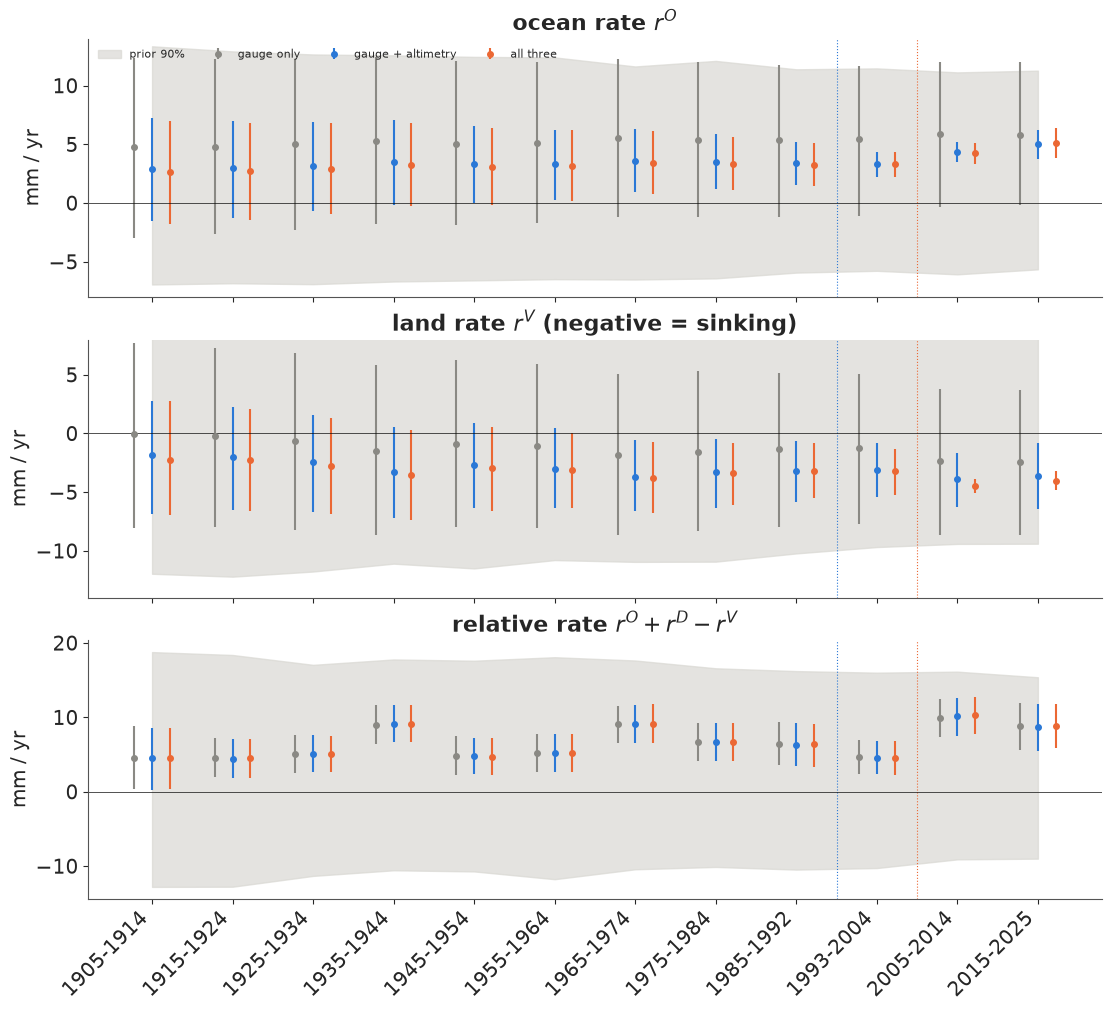

In [14]:
fits = {"gauge only": idata_tg, "gauge + altimetry": idata_ta, "all three": idata_all}
FIT_COL = {"gauge only": MUTED, "gauge + altimetry": BLUE, "all three": ORANGE}
prior_r = {v: prior.prior[v].values.reshape(-1, K) for v in ["rO", "rD", "rV"]}
prior_r["rel"] = prior_r["rO"] + prior_r["rD"] - prior_r["rV"]

fig, axs = plt.subplots(3, 1, figsize=(11, 10), sharex=True, layout="constrained")
for ax, v, lab in zip(axs, ["rO", "rV", "rel"], ["ocean rate $r^O$", "land rate $r^V$ (negative = sinking)",
                                               "relative rate $r^O + r^D - r^V$"]):
    lo, hi = np.percentile(prior_r[v], [5, 95], axis=0)
    ax.fill_between(np.arange(K), lo, hi, color=LIGHT, alpha=0.7, step=None, label="prior 90%")
    for j, (name, idata) in enumerate(fits.items()):
        p = idata.posterior
        x = (p["rO"] + p["rD"] - p["rV"]) if v == "rel" else p[v]
        x = x.values.reshape(-1, K)
        q = np.percentile(x, [5, 50, 95], axis=0)
        off = (j - 1) * 0.22
        ax.errorbar(np.arange(K) + off, q[1], yerr=[q[1] - q[0], q[2] - q[1]], fmt="o", ms=4, capsize=0,
                    color=FIT_COL[name], label=name)
    ax.axvline(8.5, color=BLUE, lw=0.8, ls=":")
    ax.axvline(9.5, color=ORANGE, lw=0.8, ls=":")
    ax.axhline(0, color=INK, lw=0.5)
    ax.set(ylabel="mm / yr", title=lab)
axs[0].legend(ncols=4, fontsize=8, loc="upper left")
axs[0].set_ylim(-8, 14)
axs[1].set_ylim(-14, 8)
axs[2].set_xticks(np.arange(K), SEG, rotation=45, ha="right");

This is the notebook in one figure. In the **relative** rate (bottom) the three fits are indistinguishable:
every instrument added after 1993 agrees with the gauge, so the gauge's answer does not change. In the **ocean**
panel (top), adding altimetry collapses the uncertainty after 1993 from the prior band to about ±1 mm/yr, and
narrows the earlier decades through the prior's random walk. In the **land** panel (middle), only the GPS
collapses the last two decades - the grey intervals are about 12 mm/yr wide, the blue ones about 5, the orange
ones under 2.
Before 1993 every interval for ocean and land is wide. Fusion changed the answer where an instrument looked,
and only there.

Identifiability has a second signature: the **posterior correlation** between the ocean and land rates
of the same decade. The gauge sees $r^O - r^V$. When that difference is all the data fix, a draw with a
faster-rising ocean must also have a faster-rising (less sinking) land to keep the difference, so the two
rates move together and their correlation approaches +1. When an instrument measures one of them, the
correlation falls towards 0.

gauge only         corr(ocean, land) by decade: +0.90 +0.94 +0.95 +0.95 +0.95 +0.95 +0.95 +0.94 +0.94 +0.94 +0.93 +0.88
gauge + altimetry  corr(ocean, land) by decade: +0.73 +0.82 +0.84 +0.82 +0.79 +0.76 +0.71 +0.64 +0.51 +0.29 +0.10 +0.14
all three          corr(ocean, land) by decade: +0.74 +0.83 +0.84 +0.82 +0.80 +0.75 +0.69 +0.61 +0.48 +0.28 +0.02 -0.02


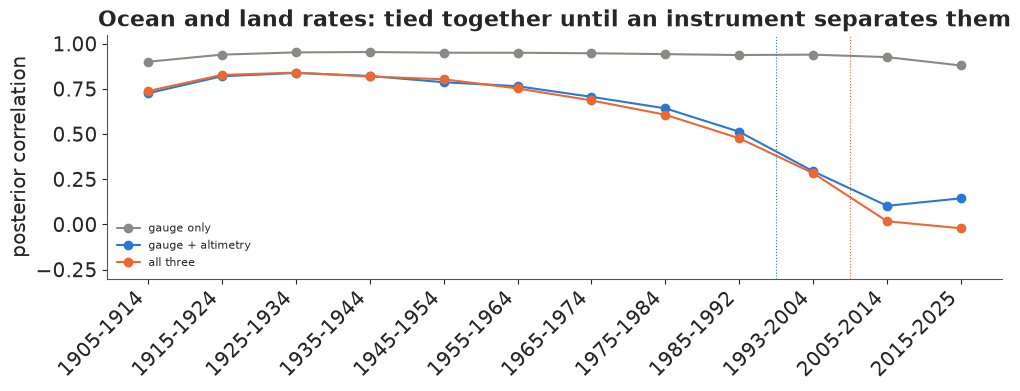

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for name, idata in fits.items():
    p = idata.posterior
    o, v = p["rO"].values.reshape(-1, K), p["rV"].values.reshape(-1, K)
    corr = [np.corrcoef(o[:, k], v[:, k])[0, 1] for k in range(K)]
    ax.plot(np.arange(K), corr, "o-", color=FIT_COL[name], label=name)
    print(f"{name:<18} corr(ocean, land) by decade:", " ".join(f"{c:+.2f}" for c in corr))
ax.axvline(8.5, color=BLUE, lw=0.8, ls=":")
ax.axvline(9.5, color=ORANGE, lw=0.8, ls=":")
ax.set_xticks(np.arange(K), SEG, rotation=45, ha="right")
ax.set(ylabel="posterior correlation", title="Ocean and land rates: tied together until an instrument separates them", ylim=(-0.3, 1.05))
ax.legend(fontsize=8);

With the gauge alone the correlation is 0.88-0.95 in every decade: the ocean and land rates are one direction
in parameter space, which only their difference pins down. Adding altimetry breaks the tie from 1993 (0.29 in
1993-2004, about 0.1 after 2005), and the tie loosens gradually as we go back towards 1993 (0.5 in 1985-1992)
because the random walk carries the satellite information backwards. In the early century the correlation is
still 0.7-0.85 with all three instruments - the split there is the prior's.

The GPS changes these correlations very little (after 2005 they were already near zero with altimetry
alone). Its contribution is invisible in this plot and obvious in the previous one: once $O$ is measured, the
land's uncertainty sits in its tie with the local departure $D$, which correlation of $O$ with $V$ does not
show. A single diagnostic rarely tells the whole identifiability story.

## E. Checking the model

### Diagnostics

All fits after the failed one ran under nutpie with 1,000 tuning steps and `target_accept=0.95` (at the
default 0.8 the full model gave a handful of divergences in trial runs). The summary in part D showed r_hat
and ESS for the noise scales; here are the rates and offsets of the full model.

In [16]:
print(az.summary(idata_all, var_names=["rO", "rV", "rD"], round_to=2)[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]].to_string())
print("offsets of the series (mm):")
print(az.summary(idata_all, var_names=["offset"], round_to=1)[["mean", "sd", "r_hat"]].to_string())

               mean    sd  ess_bulk  ess_tail  r_hat
rO[1905-1914]  2.63  2.66   1163.69   1812.97   1.00
rO[1915-1924]  2.69  2.50   1072.60   1758.90   1.00
rO[1925-1934]  2.92  2.36    949.59   1336.91   1.00
rO[1935-1944]  3.27  2.17    824.15   1246.27   1.00
rO[1945-1954]  3.07  2.02    735.94   1185.74   1.00
rO[1955-1964]  3.17  1.85    674.47   1098.35   1.00
rO[1965-1974]  3.43  1.65    554.76    840.48   1.00
rO[1975-1984]  3.33  1.42    513.25    787.69   1.00
rO[1985-1992]  3.28  1.13    555.78    826.36   1.01
rO[1993-2004]  3.29  0.63    439.89    863.64   1.01
rO[2005-2014]  4.25  0.54    380.48    575.05   1.01
rO[2015-2025]  5.08  0.77    216.43    343.56   1.01
rV[1905-1914] -2.19  2.99   1379.31   1820.56   1.00
rV[1915-1924] -2.33  2.68   1184.72   1766.54   1.00
rV[1925-1934] -2.77  2.49   1035.27   1334.10   1.00
rV[1935-1944] -3.59  2.32    844.12   1423.15   1.00
rV[1945-1954] -2.98  2.18    739.37   1149.32   1.00
rV[1955-1964] -3.15  1.96    653.86   1099.97 

Every r_hat is at most 1.02 and the smallest bulk ESS among the rates is about 220 (the ocean rate of
2015-2025, the least constrained of the recent rates, for reasons the prior swap below makes clear), enough for the means and 90%
intervals we quote. The fits each take a few seconds. The offsets read like the instruments' history: the
five mission offsets agree within a few millimetres (15-20 mm, sds 4.5-7.5), as expected for a series the
laboratory has already cross-calibrated, and the TXGA offsets jump by **26 mm** from the second antenna period
to the third - the April 2017 antenna change - with smaller steps of -8 mm (2011) and +12 mm (2021). Treating
those steps as parameters means their uncertainty (offset sds of 1.5-5.5 mm) flows into the land rate instead
of being hidden by a hand correction.

### Posterior predictive check, instrument by instrument

A model of three instruments has to reproduce each of them. We draw replicated annual values and compare
them with the data: the 90% predictive band should hold about 90% of the points of each instrument, and the
residuals should show no leftover trend or jump.

source
altimetry     1.00
gps           0.95
tide_gauge    0.94
tide_gauge: residual sd  36.0 mm, lag-1 autocorrelation +0.26
 altimetry: residual sd   1.8 mm
       gps: residual sd   1.9 mm, lag-1 autocorrelation -0.03


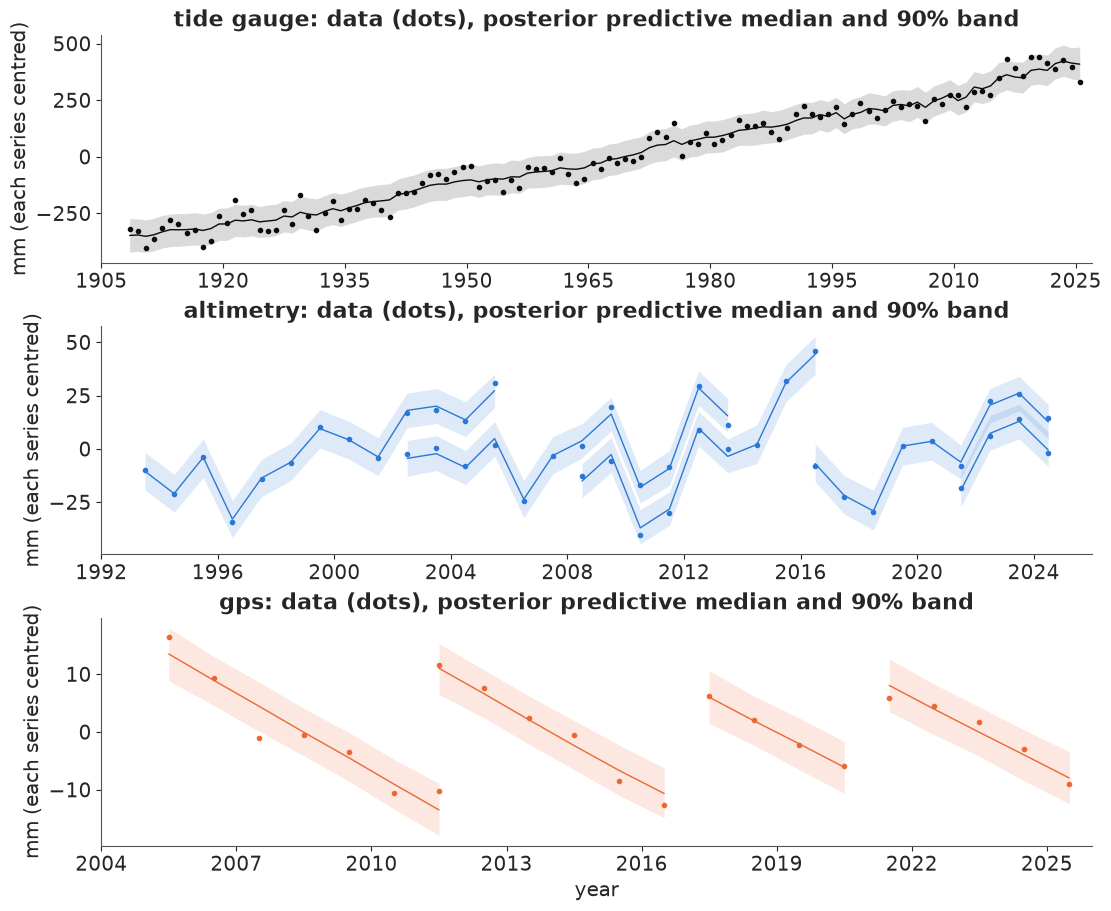

In [17]:
with m_all:
    ppc = pm.sample_posterior_predictive(idata_all, random_seed=RANDOM_SEED, progressbar=False)
yrep = ppc.posterior_predictive["y"].values.reshape(-1, len(m_all.rows))
rows_all = m_all.rows
lo, hi = np.percentile(yrep, [5, 95], axis=0)
med = np.median(yrep, axis=0)
inside = (rows_all.y >= lo) & (rows_all.y <= hi)
print(inside.groupby(rows_all.source).mean().round(2).rename("share inside 90% band").to_string())
for s in ["tide_gauge", "altimetry", "gps"]:
    r = rows_all[rows_all.source == s]
    res = (r.y - med[r.index])
    lag1 = np.corrcoef(res[:-1], res[1:])[0, 1] if s != "altimetry" else np.nan
    print(f"{s:>10}: residual sd {res.std():5.1f} mm" + ("" if np.isnan(lag1) else f", lag-1 autocorrelation {lag1:+.2f}"))

fig, axs = plt.subplots(3, 1, figsize=(11, 9), layout="constrained")
for ax, s, xlim in zip(axs, ["tide_gauge", "altimetry", "gps"], [(1905, 2027), (1992, 2026), (2004, 2026)]):
    r = rows_all[rows_all.source == s]
    for seg, rr in r.groupby("segment", sort=False):
        idx = rr.index.to_numpy()
        base = rr.y.mean()
        ax.fill_between(rr.year + 0.5, lo[idx] - base, hi[idx] - base, color=SRC_COL[s], alpha=0.15, lw=0)
        ax.plot(rr.year + 0.5, med[idx] - base, color=SRC_COL[s], lw=1)
        ax.plot(rr.year + 0.5, rr.y - base, "o", ms=3, color=SRC_COL[s])
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set(xlim=xlim, ylabel="mm (each series centred)", title=f"{s.replace('_', ' ')}: data (dots), posterior predictive median and 90% band")
axs[-1].set_xlabel("year");

The predictive bands hold 94% of the gauge's years and 95% of the GPS years: about right for 90% bands, a
little wide. The altimetry is covered 100% of the time with residuals of only 1.8 mm, half the fitted noise
scale - the latent wobble $\eta_t$ follows the altimeters closely, so their replicated values vary more than
their residuals. This check is lenient by construction: every replicated value shares the fitted $\eta_t$
of its year, which the altimeters largely determine, so it tests the instrument noise given the latent
states rather than the model's ability to predict a new year. The over-coverage is harmless for the rates. Two misfits are worth naming. The gauge
residuals keep a lag-1 autocorrelation of 0.26: wet or windy years come in short runs that independent annual
noise does not model, so the relative rates are slightly over-precise (an AR(1) gauge noise is a natural
extension). And the GPS panel shows that a straight line within each antenna period is a good description of
the land since 2005 - no visible slowdown or Harvey-related step beyond the antenna change.

### Is the split before 1993 real? Swap the ocean prior

Contraction from prior to posterior is a weak test of identification (E62). A sharper one is to change the
prior on the part the data cannot see and watch what moves. We replace the smooth ocean random walk with an
external estimate for every segment before 1993: the twentieth-century **global** mean rate of Frederikse
et al. (2020), about 1.6 mm/yr, as $\mathcal N(1.6, 0.5^2)$ in each decade, independently, and a vague prior
after 1993. If the land rates before 1993 move with this prior and those after 2005 do not, the first are
borrowed and the second are measured.

all three, global prior     8 s  divergences    0  max r_hat 1.016  min bulk ESS   283  tuning steps 1000
           ocean (smooth prior)  ocean (global prior)  ocean sd (smooth)  ocean sd (global)  land (smooth prior)  land (global prior)  land sd (global)
1905-1914                   2.6                   1.6                2.7                0.5                 -2.2                 -3.4               1.9
1915-1924                   2.7                   1.6                2.5                0.5                 -2.3                 -3.6               1.5
1925-1934                   2.9                   1.6                2.4                0.5                 -2.8                 -4.1               1.3
1935-1944                   3.3                   1.7                2.2                0.5                 -3.6                 -4.9               1.2
1945-1954                   3.1                   1.5                2.0                0.5                 -3.0                 -4.5 

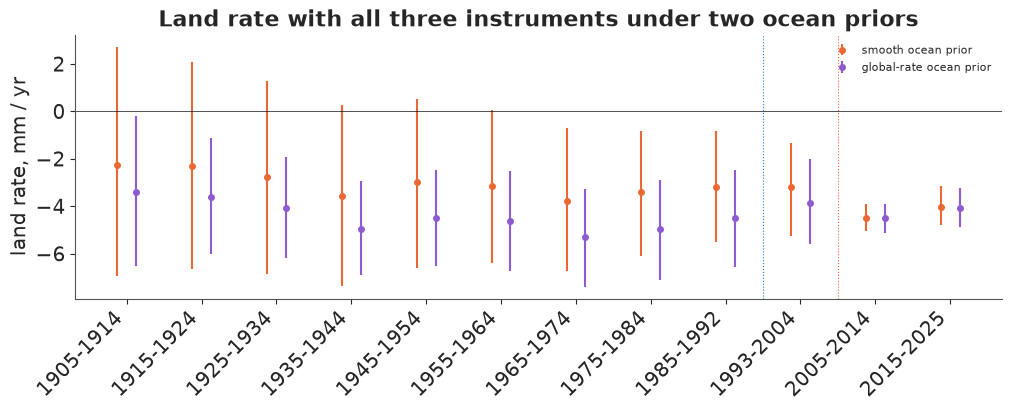

In [18]:
idata_glob = fit(build_model(ocean_prior="global"), target_accept=0.95)
health(idata_glob, "all three, global prior")
comp = pd.DataFrame({
    "ocean (smooth prior)": idata_all.posterior["rO"].mean(("chain", "draw")).values,
    "ocean (global prior)": idata_glob.posterior["rO"].mean(("chain", "draw")).values,
    "ocean sd (smooth)": idata_all.posterior["rO"].std(("chain", "draw")).values,
    "ocean sd (global)": idata_glob.posterior["rO"].std(("chain", "draw")).values,
    "land (smooth prior)": idata_all.posterior["rV"].mean(("chain", "draw")).values,
    "land (global prior)": idata_glob.posterior["rV"].mean(("chain", "draw")).values,
    "land sd (global)": idata_glob.posterior["rV"].std(("chain", "draw")).values,
}, index=SEG).round(1)
print(comp.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
for j, (name, idata, col) in enumerate([("smooth ocean prior", idata_all, ORANGE), ("global-rate ocean prior", idata_glob, PURPLE)]):
    x = idata.posterior["rV"].values.reshape(-1, K)
    q = np.percentile(x, [5, 50, 95], axis=0)
    ax.errorbar(np.arange(K) + (j - 0.5) * 0.25, q[1], yerr=[q[1] - q[0], q[2] - q[1]], fmt="o", ms=4, color=col, label=name)
ax.axvline(8.5, color=BLUE, lw=0.8, ls=":")
ax.axvline(9.5, color=ORANGE, lw=0.8, ls=":")
ax.axhline(0, color=INK, lw=0.5)
ax.set_xticks(np.arange(K), SEG, rotation=45, ha="right")
ax.set(ylabel="land rate, mm / yr", title="Land rate with all three instruments under two ocean priors")
ax.legend(fontsize=8, loc="upper right");

Before 1993 the land rates move by 1.2-1.6 mm/yr with the prior - the 1965-1974 rate goes from -3.8 to -5.3
mm/yr - so the subsidence history of the twentieth century in this model is whatever ocean history we assume
for the Gulf: with the global-mean ocean, land sank 4.5-5.3 mm/yr through the middle of the century, the
period of heavy pumping; with the smooth prior, about 3-3.8. After 2005 the land rates do not move at all
(-4.5 and -4.5; -4.0 and -4.1): **the GPS-era land is measured, the pre-satellite land is borrowed.**

The table holds a less expected result too. The ocean rates *inside* the satellite era also moved: 1993-2004
from 3.3 to 2.3 mm/yr and 2015-2025 from 5.1 to 6.4. Their sds grew as well,
from 0.5-0.8 mm/yr under the smooth prior to 1.0-1.3 under the vague one (the two ocean sd columns). Ocean
*levels* after 1993 are measured; the decadal *rates*, and so how fast the ocean **accelerates**, are still
partly prior.

A natural suspect is the five free mission offsets. We can test it directly: refit both ocean priors with a
single offset shared by all the altimetry, so that the satellite record is one continuous series.

In [19]:
def accel_of(idata):
    rO = idata.posterior["rO"].values.reshape(-1, K)
    return (rO[:, -1] - rO[:, -3]) / 21.0


one_off = {}
for prior_name in ["smooth", "global"]:
    one_off[prior_name] = fit(build_model(ocean_prior=prior_name, one_alt_offset=True), target_accept=0.95)
    health(one_off[prior_name], f"one altimetry offset, {prior_name}")
rows = []
for name, idata in [("five offsets, smooth", idata_all), ("five offsets, global", idata_glob),
                    ("one offset, smooth", one_off["smooth"]), ("one offset, global", one_off["global"])]:
    p = idata.posterior["rO"]
    mu, sd = p.mean(("chain", "draw")).values, p.std(("chain", "draw")).values
    a = accel_of(idata)
    rows.append({"fit": name, **{SEG[k]: f"{mu[k]:.1f} ± {sd[k]:.1f}" for k in range(K - 3, K)},
                 "accel (mm/yr2)": f"{np.median(a):.2f} [{np.percentile(a, 5):.2f}, {np.percentile(a, 95):.2f}]"})
print("ocean rates after 1993, mm/yr (mean ± sd), and the ocean acceleration (median, 90% interval)")
print(pd.DataFrame(rows).set_index("fit").to_string())

one altimetry offset, smooth    9 s  divergences    0  max r_hat 1.024  min bulk ESS   229  tuning steps 1000


one altimetry offset, global    9 s  divergences    0  max r_hat 1.019  min bulk ESS   278  tuning steps 1000
ocean rates after 1993, mm/yr (mean ± sd), and the ocean acceleration (median, 90% interval)
                      1993-2004  2005-2014  2015-2025     accel (mm/yr2)
fit                                                                     
five offsets, smooth  3.3 ± 0.6  4.3 ± 0.5  5.1 ± 0.8  0.08 [0.00, 0.17]
five offsets, global  2.3 ± 1.0  4.3 ± 1.0  6.4 ± 1.3  0.20 [0.07, 0.31]
one offset, smooth    3.3 ± 0.6  4.3 ± 0.5  5.4 ± 0.7  0.10 [0.02, 0.18]
one offset, global    2.2 ± 1.0  4.5 ± 1.0  6.6 ± 1.2  0.21 [0.10, 0.33]


The suspect is innocent. With one shared offset the acceleration is 0.10 [0.02, 0.18] mm/yr² under the smooth
prior and 0.21 [0.10, 0.33] under the global one, almost the 0.08 and 0.20 of the five-offset fits, and the
vague-prior ocean sds stay at 1.0-1.2 mm/yr. The missions overlap for years, so their joins cost little.

The real limit is the Gulf-wide wobble. The altimeters see $O_t + \eta_t$, and $\eta_t$ is independent from
year to year with an sd of about 16 mm, so within a decade the altimetry scatters around the ocean's trend by
16 mm, not by its own 4 mm of noise. Ten annual values scattered by 16 mm fix a slope only to about
$16/\sqrt{82.5} \approx 1.8$ mm/yr (82.5 is the sum of squared deviations of ten consecutive years from their
mean); the continuity of the level across segment boundaries brings that down to the 1.0-1.3 in the table.
The smooth random walk narrows it further by borrowing between neighbouring segments, and that borrowing is a
good part of the ±0.5-0.8 mm/yr reported in part D. This matters in the next part.

## F. What should Galveston plan for?

NOAA's 2022 scenarios for Pier 21 give relative sea level above the 2005 baseline. Our states are zero at
2005 too, so the posterior relative sea level in 2025 and the scenarios can be compared directly (NOAA's
baseline is the 1996-2014 mean, centred on 2005; ours is the trend value at 2005, a difference of a
millimetre or two for a smooth series).

In [20]:
data.describe("e97_noaa2022_scenarios")
scen = data.load("e97_noaa2022_scenarios")
sc = scen.pivot(index="year", columns="scenario", values="rsl_cm")[["Low", "Intermediate-Low", "Intermediate", "Intermediate-High", "High"]]
print(sc.loc[[2005, 2020, 2030, 2040, 2050]].to_string())
tg_check = (TG.y[TG.year.between(2021, 2025)].mean() - TG.y[TG.year.between(1996, 2014)].mean()) / 10
print(f"gauge: 2021-2025 mean minus 1996-2014 mean = {tg_check:.1f} cm")

e97_noaa2022_scenarios: scenario (Low, Intermediate-Low, Intermediate, Intermediate-High, High), year (2005, 2020, 2030, ..., 2150), rsl_cm (median relative sea level in cm above the 2005 baseline), lo_cm and hi_cm (the report's likely range, 17th-83rd percentiles), background_cm_per_yr (the API's backgroundRslPerYear field, the same for all rows).
  source: NOAA CO-OPS API, read 2026-11-04: the 2022 Sea Level Rise Technical Report scenarios (Sweet et al. 2022, NOAA Technical Report NOS 01) at Galveston Pier 21 (station 8771450, PSMSL 161). US government work, public domain. CONVERTED from the JSON answer by tools/build_e97_data.py - keep the cached file.
  url:    https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/slr_projections.json?station=8771450&units=metric
scenario   Low  Intermediate-Low  Intermediate  Intermediate-High  High
year                                                                   
2005       0.0               0.0           0.0                0.0   

The scenarios barely differ before 2030 - all five give 14-15 cm by 2020 - and fan out afterwards: 42 cm (Low)
to 63 cm (High) by 2050. The observed record therefore cannot yet say which scenario Galveston is on: the gauge's
2021-2025 mean stands 16 cm above its 1996-2014 mean, and the model's trend for mid-2025 is 20 cm, both in the
narrow range all scenarios share. The decision has to rest on an extrapolation.

A planner who wants an observation-based number for 2050 can extrapolate - and here the split matters. The
land has no reason to accelerate (pumping is regulated and the GPS shows a steady rate), while the ocean is
expected to (Nerem et al. 2018 detected acceleration in the altimetry era). We therefore project each
component by its own rule: land and local departure continue at their 2015-2025 rates; the ocean continues
at its 2015-2025 rate plus its own acceleration, estimated per draw as the change in ocean rate between the
1993-2004 and 2015-2025 segments divided by the 21 years between their centres. A gauge-only analyst who
cannot split the record has to decide how much of the gauge's acceleration is ocean; in our gauge-only fit
that decision is made by the priors.

This is a projection under **persistence**, and it is narrower than the model's own predictive spread. The
2015-2025 departure and land rates are held fixed for 25 years, although the model lets the departure take
a new rate each decade ($\mathcal N(0, 2^2)$) and the ocean and land rates take new random-walk steps; none
of those future changes are added. The intervals below are therefore parameter uncertainty under that
assumption. Redrawing the departure rate for the 2030s and 2040s alone would add about 3 cm of sd (two
decades, each 10 years times a rate of sd 2 mm/yr, so 2 cm each, combined as $\sqrt 2 \times 2$).

In [21]:
def project_2050(idata):
    p = idata.posterior
    rO, rD, rV = (p[v].values.reshape(-1, K) for v in ["rO", "rD", "rV"])
    rsl_2025 = (p["O"] + p["D"] - p["V"]).values.reshape(-1, len(YEARS))[:, -1]   # middle of 2025
    accel = (rO[:, -1] - rO[:, -3]) / 21.0                                         # mm / yr^2
    t0, h = 2020.5, 25.0          # centre of the last segment; years from mid-2025 to mid-2050
    ocean = h * rO[:, -1] + accel * ((2050.5 - t0) ** 2 - (2025.5 - t0) ** 2) / 2
    return (rsl_2025 + ocean + h * (rD[:, -1] - rV[:, -1])) / 10.0, rsl_2025 / 10.0, accel


SCEN_2050 = sc.loc[2050]
proj = {}
rows = []
for name, idata in {**fits, "all three, global prior": idata_glob}.items():
    p50, r25, acc = project_2050(idata)
    proj[name] = p50
    rows.append({"data": name, "RSL 2025 (cm)": f"{np.median(r25):.0f} [{np.percentile(r25, 5):.0f}, {np.percentile(r25, 95):.0f}]",
                 "ocean accel (mm/yr2)": f"{np.median(acc):.2f} [{np.percentile(acc, 5):.2f}, {np.percentile(acc, 95):.2f}]",
                 "RSL 2050 (cm)": f"{np.median(p50):.0f} [{np.percentile(p50, 5):.0f}, {np.percentile(p50, 95):.0f}]",
                 **{f"P(> {s})": round(float((p50 > v).mean()), 2) for s, v in SCEN_2050.items()}})
print("medians and 90% intervals; P(> scenario) = posterior probability of exceeding that scenario's 2050 median")
land_part = {n: -25 * i.posterior["rV"].values.reshape(-1, K)[:, -1] / 10 for n, i in
             {**fits, "all three, global prior": idata_glob}.items()}
print(pd.DataFrame(rows).set_index("data").to_string())
for n, lp in land_part.items():
    print(f"land sinking 2025-2050 ({n}): {lp.mean():.1f} ± {lp.std():.1f} cm")

medians and 90% intervals; P(> scenario) = posterior probability of exceeding that scenario's 2050 median
                        RSL 2025 (cm) ocean accel (mm/yr2) RSL 2050 (cm)  P(> Low)  P(> Intermediate-Low)  P(> Intermediate)  P(> Intermediate-High)  P(> High)
data                                                                                                                                                           
gauge only                19 [15, 23]   0.02 [-0.08, 0.13]   42 [29, 55]      0.51                   0.31               0.15                    0.04       0.00
gauge + altimetry         19 [15, 23]    0.08 [0.00, 0.16]   44 [32, 57]      0.62                   0.42               0.23                    0.06       0.01
all three                 20 [16, 23]    0.08 [0.00, 0.17]   45 [34, 58]      0.68                   0.46               0.26                    0.07       0.01
all three, global prior   21 [17, 24]    0.20 [0.07, 0.31]   54 [40, 68]      0.93            

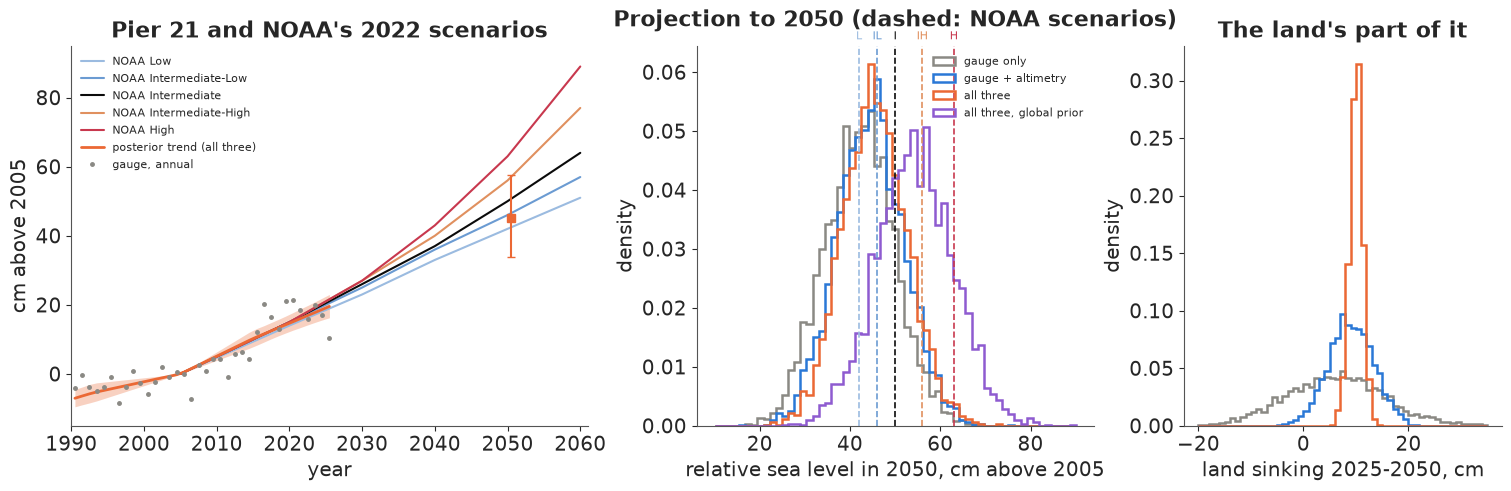

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained", width_ratios=[1.3, 1, 0.8])
ax = axs[0]
yrs_s = sc.index.to_numpy()
for s, col in zip(sc.columns, ["#9bbbe0", "#6b9bd2", INK, "#e0905f", RED]):
    ax.plot(yrs_s[yrs_s <= 2060], sc[s].to_numpy()[yrs_s <= 2060], color=col, lw=1.5, label=f"NOAA {s}")
rsl_post = (idata_all.posterior["O"] + idata_all.posterior["D"] - idata_all.posterior["V"]).values.reshape(-1, len(YEARS)) / 10
qq = np.percentile(rsl_post, [5, 50, 95], axis=0)
mask = YEARS >= 1990
ax.fill_between(YEARS[mask] + 0.5, qq[0][mask], qq[2][mask], color=ORANGE, alpha=0.3, lw=0)
ax.plot(YEARS[mask] + 0.5, qq[1][mask], color=ORANGE, lw=2, label="posterior trend (all three)")
g = TG[TG.year >= 1990]
ax.plot(g.year + 0.5, (g.y - TG.y[TG.year.between(1996, 2014)].mean()) / 10, ".", color=MUTED, ms=5, label="gauge, annual")
pq = np.percentile(proj["all three"], [5, 50, 95])
ax.errorbar([2050.5], [pq[1]], yerr=[[pq[1] - pq[0]], [pq[2] - pq[1]]], fmt="s", color=ORANGE, ms=6, capsize=3)
ax.set(xlim=(1990, 2061), ylim=(-15, 95), xlabel="year", ylabel="cm above 2005",
       title="Pier 21 and NOAA's 2022 scenarios")
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
bins = np.linspace(10, 90, 60)
for name, col in [("gauge only", MUTED), ("gauge + altimetry", BLUE), ("all three", ORANGE), ("all three, global prior", PURPLE)]:
    ax.hist(proj[name], bins=bins, density=True, histtype="step", lw=1.8, color=col, label=name)
for s, col, ab in zip(sc.columns, ["#9bbbe0", "#6b9bd2", INK, "#e0905f", RED], ["L", "IL", "I", "IH", "H"]):
    ax.axvline(SCEN_2050[s], color=col, lw=1.2, ls="--")
    ax.text(SCEN_2050[s], 1.01, ab, color=col, ha="center", va="bottom", fontsize=8, transform=ax.get_xaxis_transform())
ax.set(xlabel="relative sea level in 2050, cm above 2005", ylabel="density")
ax.set_title("Projection to 2050 (dashed: NOAA scenarios)", pad=14)
ax.legend(fontsize=8)
ax = axs[2]
bins = np.linspace(-20, 35, 56)
for name, col in [("gauge only", MUTED), ("gauge + altimetry", BLUE), ("all three", ORANGE)]:
    ax.hist(land_part[name], bins=bins, density=True, histtype="step", lw=1.8, color=col, label=name)
ax.set(xlabel="land sinking 2025-2050, cm", ylabel="density", title="The land's part of it");

Read the table from the top. The **gauge-only** projection is 42 cm [29, 55] by 2050. It is low for a reason
that has nothing to do with the data: that model must decide whether the gauge's recent acceleration is ocean
(which we project to keep accelerating) or land and departure (which we do not), and its priors give most of
it to land and departure: the relative rate rose by about 4 mm/yr between 1993-2004 and 2015-2025, but the
ocean acceleration comes out at only 0.02 mm/yr² (0.4 mm/yr over the same 21 years). **Adding altimetry**
measures the ocean's share instead: 0.08 mm/yr², about 1.7 of the 4 mm/yr. Most of the rest is the local
departure swinging from about -2 mm/yr in 1993-2004 to about 0 in 2015-2025, which we do not project to keep
changing. The median moves to 44 cm. **Adding GPS** moves it to 45 cm [34, 58] and, more
importantly, pins down the land term: 25 more years of sinking at the 2015-2025 rate is **10.0 ± 1.2 cm**,
against 9.0 ± 4.3 cm without GPS and 6 ± 9 cm from the gauge alone (right panel). That number does not care
about the ocean prior (10.2 ± 1.2 cm under the global prior).

The bigger lever is the ocean prior. With the global-rate prior the ocean acceleration is 0.20 mm/yr² and the
2050 median rises to 54 cm [40, 68]. The acceleration is the difference between two decadal ocean rates, and
part E showed that both move with the prior, with five mission offsets or with one: a ten-year rate is only
loosely fixed once the year-to-year wobble can take up part of it. The fused instruments answer the land
question firmly and the "how fast is the Gulf speeding up" question only loosely. These are extrapolations of
30 years of data, not physics; the scenarios contain physics we have not modelled.

**The decision.** The two fused projections disagree about the middle scenarios, so the choice has to work
under both. **Low** (42 cm) is weakly ruled out: the fused projection exceeds it with probability 0.68 under
the smooth ocean prior and 0.93 under the global one. **Intermediate-Low** (46 cm) is not: it sits right at
the smooth-prior median of 45 cm (P(exceed) 0.46), and only the global prior (0.84) rules it out. Planning on
it bets that the smooth prior is right about the Gulf's acceleration, the one quantity the data leave
open. For a design horizon of 2050 at Pier 21, plan on NOAA's **Intermediate** scenario (50 cm above 2005),
which lies between the two fused medians (45 and 54 cm) and stays reasonable under either prior, and test
designs against **Intermediate-High** (56 cm): the projection exceeds it with probability 0.07 under the smooth
prior and 0.43 under the global one, too likely to ignore. Flood damage grows faster than water height, which
is a second reason to plan above the lower median rather than at it. And carry the land term as its own line
in the plan: **about 10 cm of the next 25 years at the pier is the ground going down**, projected to about
±1 cm if the GPS-era rate persists, the one part of the rise that local action on groundwater and subsidence
can influence. A gauge-only analysis could not have said whether that part was 0 or 20 cm.

## Summary

* **Three instruments, three combinations.** The tide gauge sees ocean + local departure - land, the
  altimetry the Gulf-average ocean, the GPS the land. The observation matrix has rank 1 before 1993, 2 from
  1993 and 3 from 2005; posteriors of everything the data cannot see in an era are priors in disguise.
* **The gauge alone splits nothing.** Its relative rates are sharp (4.5-10 mm/yr by decade, ±1.5), but ocean
  and land sds stay at 3.7-4.8 mm/yr and their posterior correlation at 0.88-0.95 in every decade.
* **Failure and fix.** A Gulf-wide wobble plus gauge noise in a gauge-only model gave 566 divergences and
  r_hat 1.29: the gauge sees only the sum of the two variances. Merging them gave a clean fit; in the fused
  model the altimeters separate them (wobble 16 mm, gauge noise 39 mm a year).
* **Fusion moves the answer where an instrument looks.** Altimetry fixed the Gulf's rate from 1993 (3.3,
  4.3, 5.1 mm/yr by segment, with help from the smooth prior); GPS fixed the land since 2005 at -4.5 ± 0.4 and -4.0 ± 0.5 mm/yr, three to four
  times tighter than without it. The instruments close the budget within about 1.5 mm/yr.
* **Offsets as parameters.** Five mission offsets and four antenna periods were estimated, not cleaned; the
  April 2017 antenna change is a 26 mm step, about six years of subsidence at the fitted rate, that would
  otherwise hide in the land rate.
* **Swapping priors shows what is measured.** Under a global-mean ocean prior the 1965-1974 land rate moved
  from -3.8 to -5.3 mm/yr while 2005-2025 land did not move; the ocean's acceleration (0.08 vs 0.20 mm/yr²) is
  prior-sensitive even in the satellite era, because the year-to-year wobble can absorb part of each decade's
  trend (ocean-rate sds of 1.0-1.3 mm/yr under the vague prior). A fit with one
  shared altimetry offset gives the same answer (0.10 vs 0.21), so the mission joins are not the cause.
* **Decision.** Plan on NOAA Intermediate (50 cm by 2050), the scenario that stays reasonable under both ocean
  priors, and stress-test at Intermediate-High (56 cm); the fused projection is 45 [34, 58] or 54 [40, 68] cm
  depending on the prior, so Low is unlikely (P exceed 0.68-0.93) while Intermediate-Low is excluded only under
  the global prior. About 10 ± 1 cm of the rise is land subsidence if the GPS-era rate persists, a number only
  the GPS makes firm. The main limit is the ocean acceleration, which 30 years of satellite data do not pin
  down against the year-to-year wobble.

## Try it yourself

1. **A regional land field.** About 30 other GPS stations of the Nevada Geodetic Laboratory lie within 50 km
   (TXGV, TXG6, COTM, ...). Add them with a shared regional land rate and station-level departures. Does the
   land rate at Pier 21 tighten further, and how different are the island stations from those around Texas City
   and Houston, where historic subsidence was largest?
2. **Monthly resolution with persistent noise.** Model monthly values with a seasonal cycle per instrument and
   AR(1) noise for the gauge (the annual residuals kept a lag-1 autocorrelation of 0.26). How much do the
   relative and ocean rates' intervals widen, and does the ocean acceleration change?
3. **A second gauge and an explicit acceleration.** Add the PSMSL record of a nearby gauge (Freeport or Sabine
   Pass) sharing the ocean state, and replace the decadal ocean rates after 1993 by a quadratic with an
   acceleration parameter. Does a second gauge make the 2050 projection less sensitive to the ocean prior?

In [23]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 80 s
